## Business Objective:

### The goal of this project is to build a machine learning model that predicts the selling price of cars based on their features (such as age, mileage, fuel type, brand, horsepower, etc.).

## Step 1: Data Gathering:

In [2]:
import pandas as pd 
path = r"D:\ML\DataSets\car_price_prediction.csv"
df = pd.read_csv(path)
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


## Step: 2 Data Quality Checks

In [3]:
df.shape

(19237, 18)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  str    
 3   Manufacturer      19237 non-null  str    
 4   Model             19237 non-null  str    
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  str    
 7   Leather interior  19237 non-null  str    
 8   Fuel type         19237 non-null  str    
 9   Engine volume     19237 non-null  str    
 10  Mileage           19237 non-null  str    
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  str    
 13  Drive wheels      19237 non-null  str    
 14  Doors             19237 non-null  str    
 15  Wheel             19237 non-null  str    
 16  Color             19237 non-null  str    
 17  Airb

In [5]:
df.isna().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [6]:
df.dtypes

ID                    int64
Price                 int64
Levy                    str
Manufacturer            str
Model                   str
Prod. year            int64
Category                str
Leather interior        str
Fuel type               str
Engine volume           str
Mileage                 str
Cylinders           float64
Gear box type           str
Drive wheels            str
Doors                   str
Wheel                   str
Color                   str
Airbags               int64
dtype: object

In [7]:
df.duplicated().sum()

np.int64(313)

In [8]:
df = df.drop_duplicates()

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.shape

(18924, 18)

In [11]:
df = pd.get_dummies(df, columns=['Fuel type'], dtype=int)

In [12]:
# df['Mileage'] = df['Mileage'].replace(' km', '', regex=False)
# df['Mileage']

In [13]:
updated = []
for i in df['Mileage']:
    data = i.split()
    updated.append(data[0])
updated = list(map(int,updated))
updated

[186005,
 192000,
 200000,
 168966,
 91901,
 160931,
 258909,
 216118,
 398069,
 128500,
 184467,
 0,
 350000,
 138038,
 76000,
 74146,
 121840,
 54317,
 295059,
 364523,
 112645,
 187000,
 39709,
 230000,
 0,
 210000,
 0,
 169000,
 158787,
 420550,
 180000,
 175056,
 200000,
 287274,
 250000,
 162000,
 10200,
 158000,
 103490,
 382746,
 203200,
 61057,
 11200,
 141000,
 160259,
 239342,
 128000,
 100734,
 141500,
 147000,
 87768,
 264014,
 132542,
 1600,
 87000,
 260000,
 5323,
 87112,
 204318,
 22000,
 83000,
 170000,
 312118,
 130000,
 200279,
 719847,
 154672,
 110969,
 225510,
 210000,
 148105,
 255456,
 111643,
 84506,
 288000,
 75000,
 94362,
 175000,
 263190,
 193614,
 264877,
 27656,
 16000,
 0,
 195053,
 121362,
 69191,
 83000,
 40772,
 172000,
 433811,
 350000,
 148213,
 103246,
 105394,
 160000,
 333333,
 0,
 214000,
 123346,
 80827,
 64464,
 91760,
 275240,
 300000,
 318400,
 91200,
 137802,
 151586,
 107000,
 210408,
 100567,
 86000,
 122740,
 144000,
 150000,
 100000,
 1

In [14]:
df['Mileage'] = updated
df['Mileage']

0        186005
1        192000
2        200000
3        168966
4         91901
          ...  
19232    300000
19233    161600
19234    116365
19235     51258
19236    186923
Name: Mileage, Length: 18924, dtype: int64

In [15]:
df.info()

<class 'pandas.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18924 non-null  int64  
 1   Price                     18924 non-null  int64  
 2   Levy                      18924 non-null  str    
 3   Manufacturer              18924 non-null  str    
 4   Model                     18924 non-null  str    
 5   Prod. year                18924 non-null  int64  
 6   Category                  18924 non-null  str    
 7   Leather interior          18924 non-null  str    
 8   Engine volume             18924 non-null  str    
 9   Mileage                   18924 non-null  int64  
 10  Cylinders                 18924 non-null  float64
 11  Gear box type             18924 non-null  str    
 12  Drive wheels              18924 non-null  str    
 13  Doors                     18924 non-null  str    
 14  Wheel                 

In [16]:
df.shape

(18924, 24)

## EDA:

In [17]:
# Descriptive Statistics
df.describe().apply(lambda x: x.apply('{:.2f}'.format))

,ID,Price,Prod. year,Mileage,Cylinders,Airbags,Fuel type_CNG,Fuel type_Diesel,Fuel type_Hybrid,Fuel type_Hydrogen,Fuel type_LPG,Fuel type_Petrol,Fuel type_Plug-in Hybrid
count,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00
mean,45575381.03,18587.44,2010.91,1555372.72,4.58,6.57,0.02,0.21,0.19,0.00,0.05,0.53,0.00
std,937546.82,192135.63,5.67,48802205.32,1.20,4.32,0.16,0.41,0.39,0.01,0.21,0.50,0.07
min,20746880.00,1.00,1939.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,45695007.50,5331.00,2009.00,70195.75,4.00,4.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,45771914.50,13172.00,2012.00,126400.00,4.00,6.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
75%,45801742.25,22063.00,2015.00,189119.75,4.00,12.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
max,45816654.00,26307500.00,2020.00,2147483647.00,16.00,16.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


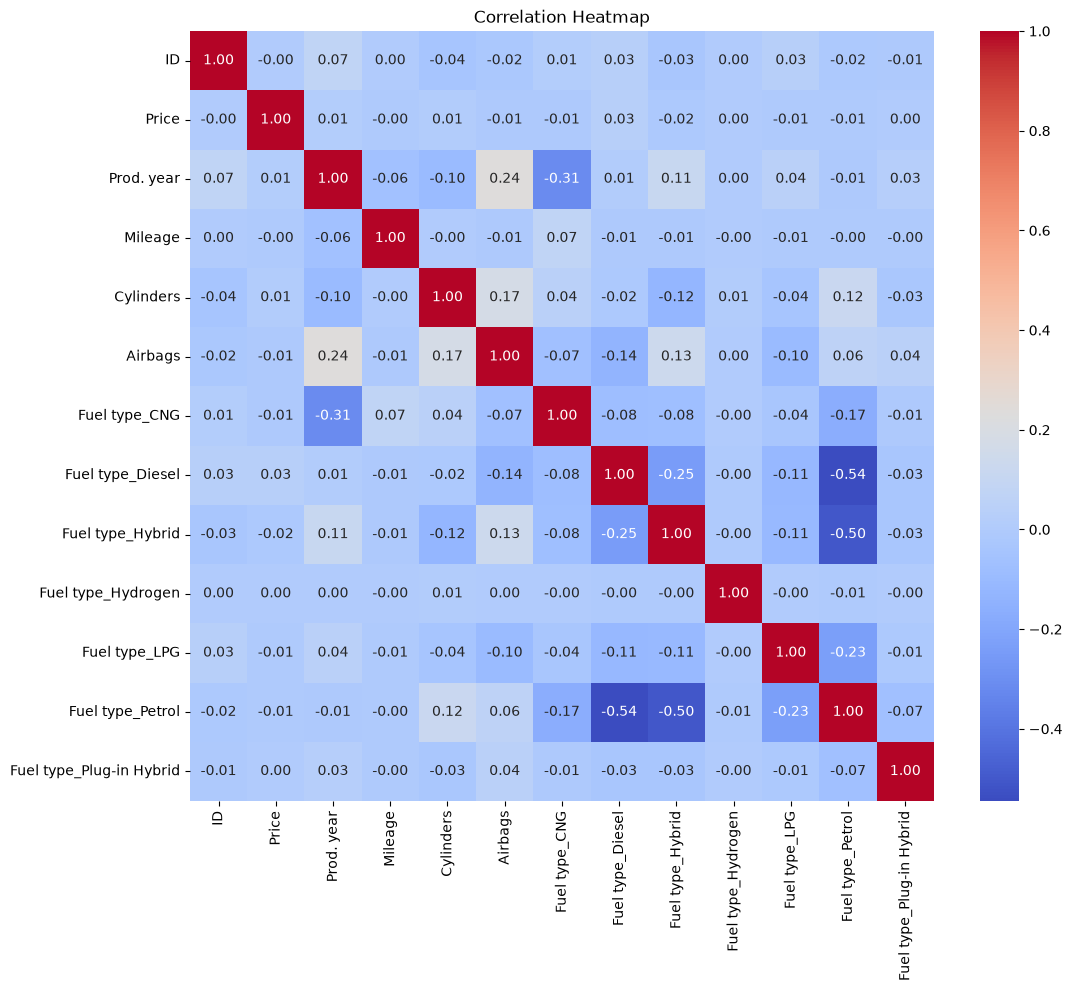

In [18]:
# Correlation Heatmap
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

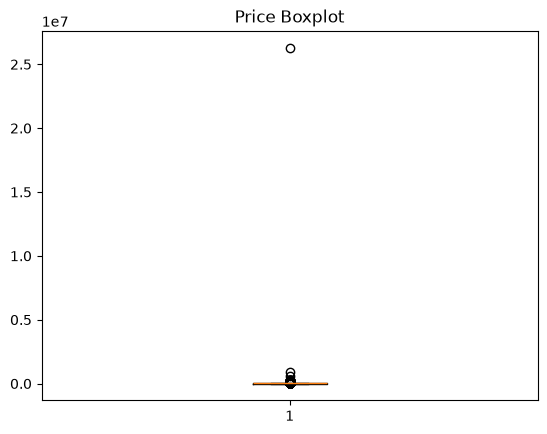

In [19]:
# Boxplot
import matplotlib.pyplot as plt

plt.boxplot(df["Price"])
plt.title("Price Boxplot")
plt.show()

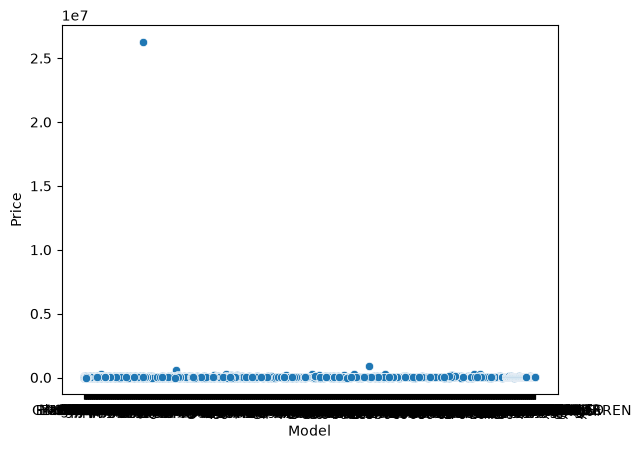

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df, x="Model", y="Price")

plt.show()

## Model Building

In [23]:
X = df.drop(columns=['ID','Price'])
Y = df[['Price']]

display(X.head())
print('--------------')
display(Y.head())

,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Engine volume,Mileage,Cylinders,Gear box type,...,Wheel,Color,Airbags,Fuel type_CNG,Fuel type_Diesel,Fuel type_Hybrid,Fuel type_Hydrogen,Fuel type_LPG,Fuel type_Petrol,Fuel type_Plug-in Hybrid
0,1399,LEXUS,RX 450,2010,Jeep,Yes,3.5,186005,6.0,Automatic,...,Left wheel,Silver,12,0,0,1,0,0,0,0
1,1018,CHEVROLET,Equinox,2011,Jeep,No,3,192000,6.0,Tiptronic,...,Left wheel,Black,8,0,0,0,0,0,1,0
2,-,HONDA,FIT,2006,Hatchback,No,1.3,200000,4.0,Variator,...,Right-hand drive,Black,2,0,0,0,0,0,1,0
3,862,FORD,Escape,2011,Jeep,Yes,2.5,168966,4.0,Automatic,...,Left wheel,White,0,0,0,1,0,0,0,0
4,446,HONDA,FIT,2014,Hatchback,Yes,1.3,91901,4.0,Automatic,...,Left wheel,Silver,4,0,0,0,0,0,1,0


--------------


,Price
0,13328
1,16621
2,8467
3,3607
4,11726


## Splitting the Data into Train and Test Sets.

In [25]:
from sklearn.model_selection import train_test_split
xtrain1,xtest1,ytrain1,ytest1 = train_test_split(X,Y,train_size=0.8,random_state=21)

In [29]:
print(xtrain1.shape,xtest1.shape)

(15139, 22) (3785, 22)


In [31]:
print(ytrain1.shape,ytest1.shape)

(15139, 1) (3785, 1)


## Data Preprocessing And Data Cleaning

In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

cat = list(X.select_dtypes(include='str').columns) 
con = list(X.select_dtypes(include='number').columns)

num_pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler())

cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore',sparse_output=False))

pre = ColumnTransformer([('cat',cat_pipe,cat),
                         ('con',num_pipe,con)]).set_output(transform='pandas')

pre

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('con', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [32]:
pre.fit(xtrain1)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('con', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [33]:
xtrain1_pre = pre.transform(xtrain1)
xtest1_pre = pre.transform(xtest1)

In [34]:
xtrain1_pre.head()

,cat__Levy_-,cat__Levy_1011,cat__Levy_1016,cat__Levy_1017,cat__Levy_1018,cat__Levy_1024,cat__Levy_1030,cat__Levy_1031,cat__Levy_1032,cat__Levy_1036,...,con__Mileage,con__Cylinders,con__Airbags,con__Fuel type_CNG,con__Fuel type_Diesel,con__Fuel type_Hybrid,con__Fuel type_Hydrogen,con__Fuel type_LPG,con__Fuel type_Petrol,con__Fuel type_Plug-in Hybrid
12356,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.026270,1.178547,-0.125426,-0.159808,-0.518946,-0.482304,-0.008128,-0.22297,0.955985,-0.065666
13896,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.024424,-0.480713,-0.589177,-0.159808,-0.518946,-0.482304,-0.008128,-0.22297,0.955985,-0.065666
15421,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.024910,-0.480713,-0.589177,-0.159808,-0.518946,-0.482304,-0.008128,-0.22297,0.955985,-0.065666
505,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.022144,-0.480713,-0.589177,-0.159808,1.926983,-0.482304,-0.008128,-0.22297,-1.046042,-0.065666
17577,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.023380,-0.480713,-1.516677,-0.159808,-0.518946,2.073382,-0.008128,-0.22297,-1.046042,-0.065666


## Model Building 

## Algorithm Evaluation

In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score

In [36]:
dct = {
    'Linear': LinearRegression(),
    'DecisionTree': DecisionTreeRegressor(),
    'RandomForest': RandomForestRegressor(),
    'GradientBoosting': GradientBoostingRegressor(),
    'XGBoost': XGBRegressor()
}

In [37]:
dct.items()

dict_items([('Linear', LinearRegression()), ('DecisionTree', DecisionTreeRegressor()), ('RandomForest', RandomForestRegressor()), ('GradientBoosting', GradientBoostingRegressor()), ('XGBoost', XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...))])

In [41]:
from sklearn.metrics import r2_score

# 1. Initialize an empty list for R2 scores
r2_scores = []

# 2. Run the loop for all 5 regression algorithms
for name, model in dct.items():
    
    # ---> THIS IS WHERE YOU ADD x_sampl AND y_sampl <---
    # Fit the model using your training features and training target
    model.fit(xtrain1_pre, ytrain1) 
    
    # 3. Predict the continuous results using your test features
    ypred_test = model.predict(xtest1_pre)
    
    # 4. Calculate the R2 score comparing real test targets to your predictions
    r2 = r2_score(ytest1, ypred_test)
    
    # 5. Append the rounded score to your list
    r2_scores.append(round(r2, 2))
    
    # Print the individual model performance
    print(f"{name} R2 Score: {round(r2, 2)}")

print("\nAll Final R2 Scores:", r2_scores)

Linear R2 Score: -0.0
DecisionTree R2 Score: 0.0


d:\ML\repository\venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForest R2 Score: 0.0


d:\ML\repository\venv\Lib\site-packages\sklearn\ensemble\_gb.py:691: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


GradientBoosting R2 Score: 0.0
XGBoost R2 Score: 0.0

All Final R2 Scores: [-0.0, 0.0, 0.0, 0.0, 0.0]


In [ ]:
res = {
    'Name': list(dct.keys()),
    'F1_score': f1_scores
}
df_res = pd.DataFrame(res)
df_res.sort_values(by='F1_score',ascending=False)